# 08 · From scalar levels to vector quantization (VQ): a starter

Everything so far quantized **each weight on its own** (scalar quantization). Vector quantization quantizes **groups
of $d$ weights jointly** to codewords in $\mathbb{R}^d$. At the same bits per weight it can only do better, and it is
how the best 2-bit LLM methods work today. This notebook is a **starter**: it explains the idea, shows it on real
weights, and leaves the experiments (Steps 4–6) to you, with skeletons.

| Step | What you will see |
|---|---|
| 1 | VQ in two equations, and why it beats scalar quantization at equal bits |
| 2 | a picture: scalar grid vs VQ Voronoi cells on correlated weight pairs |
| 3 | MSE at 2 bits/weight: scalar Lloyd vs VQ with $d=2$ and $d=4$, including the codebook cost |
| 4 | PTQ of the tiny LM of notebook 06 with VQ |
| 5 | **exercise**: QAT through the assignment, STE vs soft assignment (+ anchor) |
| 6 | a menu of VQ variants to test |

**Tags** (see notebook 00): 📘 common practice · 📗 known, less common · 🧪 new or modified in vvtk_quant.

> 📗 **Known, less common in general, but the state of the art at 2 bits for LLMs.** Read: AQLM (Egiazarian et al.,
> arXiv:2401.06118) and the classic theory in Gray & Neuhoff, *Quantization* (1998), §V. k-means codebooks for
> compression go back to Linde, Buzo & Gray (1980). `vvtk_quant/vq.py` is a small starter, not an implementation of any
> of these papers.

In [15]:
import os, sys, copy, math, time
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from vvtk_quant import VVTK_QModel
import matplotlib.pyplot as plt
from vvtk_quant import lloyd_levels, mse
from vvtk_quant.vq import kmeans, groups, assign, vq_mse, bits_per_weight, vq_wrap, vq_anchor_loss
from common_seq import DEVICE, OUT, tiny_shakespeare, CharLM, lm_batch, lm_eval, lm_sample, cosine
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## Step 1 · VQ in two equations

Cut the weights into groups $\mathbf{g} \in \mathbb{R}^d$ (here: $d$ consecutive weights of a row). A **codebook**
$\{\mathbf{c}_1,\dots,\mathbf{c}_K\}$ replaces each group by its nearest codeword:

$$Q(\mathbf{g}) = \mathbf{c}_{k^*}, \qquad k^* = \arg\min_k \lVert \mathbf{g} - \mathbf{c}_k \rVert^2 .$$

Cost: $\log_2 K$ bits per **group**, so $\log_2 K / d$ bits per weight, plus the codebook ($K d$ floats per tensor).
2 bits/weight: $(d,K) = (1,4), (2,16), (4,256)$. The MSE-optimal codebook satisfies the same two conditions as
Lloyd-Max (notebook 02), now in $d$ dimensions: **Voronoi cells** (nearest neighbour) and **centroids**. Iterating
them is k-means, the Linde–Buzo–Gray (LBG) algorithm.

Why VQ wins at equal bits (Gray & Neuhoff 1998): (i) it can follow **correlations** between weights in a group;
(ii) it can follow the **shape** of the joint density; (iii) even for independent weights, Voronoi cells in $d$
dimensions fill space better than cubes (the "space-filling" gain, small but positive).

> 📘 Scalar Lloyd-Max is the $d=1$ case: everything in notebooks 02–07 is a special case of VQ.

## Step 2 · A picture: correlated weight pairs

4000 pairs $(w_1, w_2)$ with correlation 0.8. Left: the scalar 2-bit grid, i.e. 4 levels per axis, so 16 cells that
are rectangles aligned with the axes. Right: 16 VQ codewords from k-means, the same 4 bits per pair.

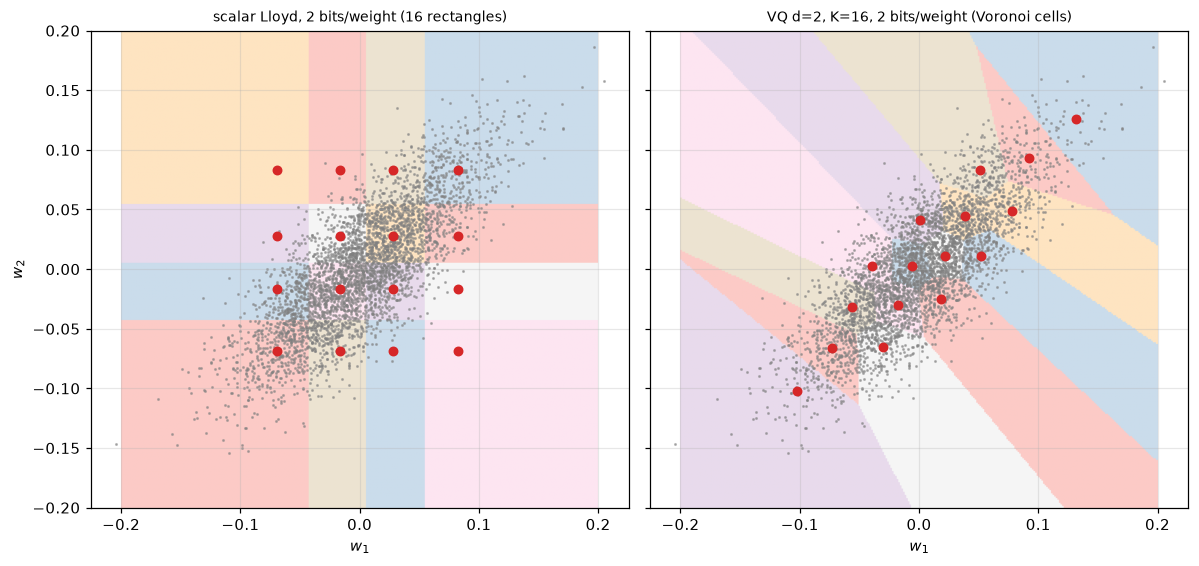

MSE scalar 2.96e-04  |  VQ 1.59e-04  (47 % lower, same bits)


In [2]:
torch.manual_seed(0)
n = 4000
a = torch.randn(n)
pairs = torch.stack([a, 0.8 * a + 0.6 * torch.randn(n)], 1) * 0.05
lv = torch.tensor(lloyd_levels(pairs.flatten().numpy(), b=2), dtype=torch.float32)
cb = kmeans(pairs, 16, iters=50)

def scalar_q(x, lv):
    lim = (lv[:-1] + lv[1:]) / 2
    return lv[torch.searchsorted(lim, x.contiguous())]

fig, ax = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
gx, gy = torch.meshgrid(torch.linspace(-0.2, 0.2, 300), torch.linspace(-0.2, 0.2, 300), indexing="xy")
grid = torch.stack([gx.flatten(), gy.flatten()], 1)
cell_s = (torch.searchsorted((lv[:-1] + lv[1:]) / 2, grid[:, 0].contiguous()) * 4
          + torch.searchsorted((lv[:-1] + lv[1:]) / 2, grid[:, 1].contiguous()))
cell_v = assign(grid, cb)
for k, (cell, title, pts) in enumerate([(cell_s, "scalar Lloyd, 2 bits/weight (16 rectangles)", torch.cartesian_prod(lv, lv)),
                                       (cell_v, "VQ d=2, K=16, 2 bits/weight (Voronoi cells)", cb)]):
    ax[k].imshow(cell.view(300, 300).numpy() % 7, extent=(-0.2, 0.2, -0.2, 0.2), origin="lower", cmap="Pastel1", alpha=0.7)
    ax[k].scatter(pairs[:, 0], pairs[:, 1], s=1, color="gray", alpha=0.5)
    ax[k].scatter(pts[:, 0], pts[:, 1], color="C3", s=30, zorder=3)
    ax[k].set_title(title, fontsize=9); ax[k].set_xlabel("$w_1$")
ax[0].set_ylabel("$w_2$"); plt.tight_layout(); plt.show()
e_s = (torch.stack([scalar_q(pairs[:, 0], lv), scalar_q(pairs[:, 1], lv)], 1) - pairs).pow(2).mean()
e_v = (cb[assign(pairs, cb)] - pairs).pow(2).mean()
print(f"MSE scalar {e_s:.2e}  |  VQ {e_v:.2e}  ({100 * (1 - e_v / e_s):.0f} % lower, same bits)")

Scalar quantization wastes codewords in the empty corners (top-left, bottom-right); VQ puts them along the
diagonal where the pairs live.

## Step 3 · MSE at 2 bits/weight on the tiny LM's real weights

We load the float char-LM of notebook 06 (run it first) and quantize each `nn.Linear` weight matrix with scalar
Lloyd ($d=1, K=4$) and VQ ($d=2, K=16$; $d=4, K=256$). The codebook is not free: with 16-bit codewords the overhead
is $16Kd/N$ bits per weight for a tensor of $N$ weights.

In [ ]:
train_ids, val_ids, itos = tiny_shakespeare()
CTX = 256
model = CharLM(len(itos), d=256, layers=4, heads=4).to(DEVICE)
ckpt = os.path.join(OUT, "charlm_fp32.pth")
assert os.path.exists(ckpt), "run notebook 06 first (it trains and saves the float model)"
model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
val_fp32 = lm_eval(model, val_ids, CTX)
lin = [(n, m) for n, m in model.named_modules() if isinstance(m, nn.Linear)]
print(f"float val loss {val_fp32:.3f}; {len(lin)} Linear layers")

configs = [(1, 4), (2, 16), (4, 256)]
print(f"{'layer':<18} {'N':>8} | " + " | ".join(f"d={d},K={K}: MSE  (bits/w)" for d, K in configs))
tot = {c: [0.0, 0.0, 0] for c in configs}
for n_, m in lin:
    w = m.weight.detach().float()
    row = []
    for d, K in configs:
        c = kmeans(groups(w, d), K, iters=30)
        e = vq_mse(w, c, d); bpw = bits_per_weight(w.numel(), K, d)
        row.append(f"{e:.2e} ({bpw:.3f})")
        tot[(d, K)][0] += e * w.numel(); tot[(d, K)][1] += bpw * w.numel(); tot[(d, K)][2] += w.numel()
    if n_.endswith(("0.q", "0.ff1", "head")):
        print(f"{n_:<18} {w.numel():>8} | " + " | ".join(row))
print("-" * 90)
for (d, K), (e, b, N) in tot.items():
    print(f"all layers d={d}, K={K:<3}: mean MSE {e / N:.3e}   bits/weight incl. codebook {b / N:.3f}")

/tmp/ipykernel_554510/765242462.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(ckpt, map_location=DEVICE))


float val loss 1.494; 25 Linear layers
layer                     N | d=1,K=4: MSE  (bits/w) | d=2,K=16: MSE  (bits/w) | d=4,K=256: MSE  (bits/w)
blocks.0.q            65536 | 2.32e-04 (2.001) | 2.21e-04 (2.008) | 1.81e-04 (2.250)
blocks.0.ff1         262144 | 1.63e-04 (2.000) | 1.57e-04 (2.002) | 1.42e-04 (2.062)
head                  16640 | 8.76e-04 (2.004) | 8.06e-04 (2.031) | 5.58e-04 (2.985)
------------------------------------------------------------------------------------------
all layers d=1, K=4  : mean MSE 2.038e-04   bits/weight incl. codebook 2.001
all layers d=2, K=16 : mean MSE 1.920e-04   bits/weight incl. codebook 2.004
all layers d=4, K=256: mean MSE 1.650e-04   bits/weight incl. codebook 2.130


## Step 4 · Exercise: PTQ of the tiny LM with VQ

**Your turn.** Step 3 measured weight MSE; what matters is the validation loss. Replace every `nn.Linear` of the
float model by a VQ version and evaluate, for the three 2-bit configurations, without training. Compare with the scalar
PTQ rows of notebook 06 (uniform / eqprob / Lloyd at 2 bits).

Tools: `vq_wrap(model, d, K, mode="hard")` replaces the layers in place and returns them; `lm_eval(model, val_ids, CTX)`
gives nats/char. Keep a float copy (`copy.deepcopy`).

Questions to answer in your report:
1. Does the ranking of Step 3 (MSE) hold for validation loss? (Notebook 03 showed that it does not always.)
2. How much of the gain survives once you count the codebook bits (`bits_per_weight`)?
3. Is the gain the same in every layer type (`q,k,v,o`, `ff1`, `ff2`, `head`)? Quantize one type at a time.

In [4]:
def vq_ptq(d, K, tipo):
    m = copy.deepcopy(model)
    # TODO: wrap m with vq_wrap(..., mode="hard") and return lm_eval(m, val_ids, CTX)
    # recoge los pesos de cada capa, los divide en grupos de d pesos consecutivos, construye un codebook de K vectores, sustituye cada vector original por el vector del codebook más cercano que minimice distorsión
    q=vq_wrap(m,d=d,K=K,mode="hard",skip=tipo)
    m.eval()
    return lm_eval(m,val_ids,CTX)


In [5]:
for d, K in configs:
     print(d, K, vq_ptq(d, K, "q"))

1 4 1.6339954435825348
2 16 1.6127294301986694
4 256 1.582049262523651


In [6]:
# Ganancia en cada tipo de capa
tipos=("q","k","v","o","ff1","ff2","head")
for type in tipos:
    for d, K in configs:
        loss=vq_ptq(d, K, type)
        print(f"Tipo {type}: d={d}, K={K}, Val Loss={loss:.4f}")

Tipo q: d=1, K=4, Val Loss=1.6340
Tipo q: d=2, K=16, Val Loss=1.6125
Tipo q: d=4, K=256, Val Loss=1.5822
Tipo k: d=1, K=4, Val Loss=1.5195
Tipo k: d=2, K=16, Val Loss=1.5074
Tipo k: d=4, K=256, Val Loss=1.5076
Tipo v: d=1, K=4, Val Loss=1.6284
Tipo v: d=2, K=16, Val Loss=1.5922
Tipo v: d=4, K=256, Val Loss=1.5798
Tipo o: d=1, K=4, Val Loss=1.5195
Tipo o: d=2, K=16, Val Loss=1.5074
Tipo o: d=4, K=256, Val Loss=1.5076
Tipo ff1: d=1, K=4, Val Loss=1.5625
Tipo ff1: d=2, K=16, Val Loss=1.5436
Tipo ff1: d=4, K=256, Val Loss=1.5289
Tipo ff2: d=1, K=4, Val Loss=1.5734
Tipo ff2: d=2, K=16, Val Loss=1.5492
Tipo ff2: d=4, K=256, Val Loss=1.5361
Tipo head: d=1, K=4, Val Loss=1.6439
Tipo head: d=2, K=16, Val Loss=1.6217
Tipo head: d=4, K=256, Val Loss=1.5844


Se mantiene el orden: la configuración que menor MSE nos daba tiene también el menor validation loss, aunque no tiene por qué ser así siempre
Con d=4 se necesita más memoria
Val loss disminuye con el aumento de d y K en todos los casos, aunque la ganancia no es la misma, depende del tipo de capa.  Menor val loss con tipo k, mayor con q

## Step 5 · Exercise: QAT through the assignment

`VQLinear` (`vvtk_quant/vq.py`) supports three training modes for the nearest-codeword lookup:

* `mode="ste"`: forward $\mathbf{c}_{k^*}$, backward identity, as in VQ-VAE. 📘 in VQ-VAEs, 📗 for weight QAT.
* `mode="soft"`: forward $\sum_k p_k \mathbf{c}_k$ with $p_k \propto \exp\!\big(-\lVert\mathbf{g}-\mathbf{c}_k\rVert^2/(\tau s^2)\big)$,
  $s$ the typical distance between neighbouring codewords, $\tau$ annealed towards 0 (set `layer.tau` each step).
  📗 soft-to-hard VQ (Agustsson et al. 2017, arXiv:1704.00648) applied to weights: the VQ analogue of the soft
  staircase.
* 🧪 `anchor_lambda > 0`: adds $\lambda\,\overline{\lVert \mathbf{g} - Q(\mathbf{g}) \rVert^2}/s^2$; you must add
  `vq_anchor_loss(layers)` to your training loss (this starter does **not** fuse it in the backward pass the way
  `QLinear` does; porting `FusedQuant` to VQ is a good engineering task).

The codebooks are fixed after k-means; only the weights move. `VQLinear` evaluates the hard model in `eval()`.

**Your turn.** Write the QAT loop: reuse `train_lm` from notebook 06 (copy it here) with a `step_hook` that anneals
`tau` for soft layers. Compare, at 2 bits/weight and the **same budget as notebook 06** (600 steps, AdamW $3\cdot10^{-4}$):
`d=1,K=4` vs `d=2,K=16`, each with STE, soft, soft + anchor. Plot the validation curves, report a table, and, before any
conclusion, run 3 seeds. Sanity check: `d=1,K=4` with STE should land close to `ste-lloyd` of notebook 06.

In [21]:
def train_lm(model, steps, lr, step_hook=None, seed=0, log_every=500, wd=0.1):
    opt = torch.optim.AdamW(model.parameters(), lr, betas=(0.9, 0.95), weight_decay=wd)
    sched = cosine(opt, steps, warmup=min(200, steps // 10))
    g = torch.Generator().manual_seed(seed)
    curve = []
    t0 = time.time()
    for s in range(steps):
        model.train()
        if step_hook is not None:
            step_hook(s, steps)
        x, y = lm_batch(train_ids, BATCH, CTX, g)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=DEVICE.type == "cuda"):
            loss = F.cross_entropy(model(x).flatten(0, 1).float(), y.flatten())
        opt.zero_grad(set_to_none=True); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        if (s + 1) % log_every == 0 or s + 1 == steps:
            v = lm_eval(model, val_ids, CTX)
            curve.append((s + 1, v))
            print(f"    step {s + 1:>5}/{steps}  train {loss.item():.3f}  val {v:.3f}  ({time.time() - t0:.0f}s)")
    return curve
def wrap(m, b, method, **kw):
    q = VVTK_QModel(copy.deepcopy(m), b=b, module_types=[nn.Linear], **kw)
    q.calibrate_quant(method=method)
    return q

In [19]:
# TODO (skeleton)
m = copy.deepcopy(model)
layers = vq_wrap(m, d=2, K=16, mode="soft", tau=1.0, anchor_lambda=0.0)
def hook(step, n_steps):
    for l in layers:
        l.tau =  1.0 * (0.02 / 1.0) ** (step / (n_steps - 1))   # descenso geométrico e.g. geometric 1.0 -> 0.02

In [20]:
hist = train_lm(m,steps=600,lr=3e-4,step_hook=hook)

    step   500/600  train 1.168  val 1.497  (171s)
    step   600/600  train 1.168  val 1.495  (208s)


--- fp32
    step   100/600  train 1.159  val 1.505  (29s)
    step   200/600  train 1.135  val 1.505  (59s)
    step   300/600  train 1.132  val 1.502  (88s)
    step   400/600  train 1.145  val 1.506  (118s)
    step   500/600  train 1.112  val 1.505  (147s)
    step   600/600  train 1.093  val 1.505  (177s)
--- ste-uniform, 3 bits
    step   100/600  train 1.315  val 1.544  (31s)
    step   200/600  train 1.280  val 1.549  (62s)
    step   300/600  train 1.262  val 1.532  (93s)
    step   400/600  train 1.272  val 1.525  (124s)
    step   500/600  train 1.221  val 1.521  (156s)
    step   600/600  train 1.194  val 1.505  (187s)
--- ste-lloyd, 3 bits
    step   100/600  train 1.196  val 1.501  (31s)
    step   200/600  train 1.175  val 1.508  (62s)
    step   300/600  train 1.162  val 1.503  (93s)
    step   400/600  train 1.183  val 1.504  (124s)
    step   500/600  train 1.137  val 1.497  (156s)
    step   600/600  train 1.121  val 1.496  (187s)
--- soft-lloyd, 3 bits
    step   10

/tmp/ipykernel_554510/2493146668.py:37: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(c[:, 0], c[:, 1], "o-", ms=3, label=name, ls="--" if name == "fp32" else "-")


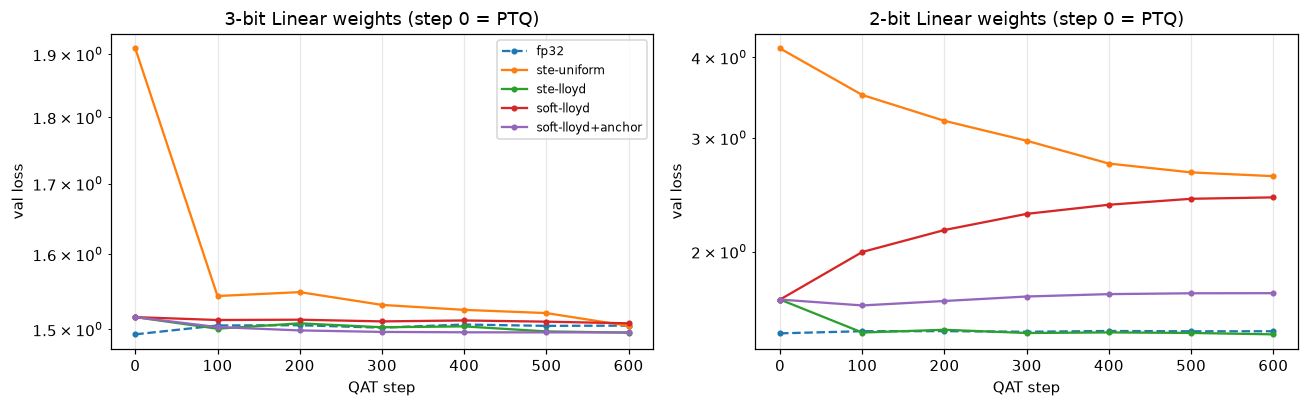

contender            |          3-bit |          2-bit   (val nats/char, PTQ -> QAT)
fp32                 | 1.494 -> 1.505 | 1.494 -> 1.505
ste-uniform          | 1.910 -> 1.505 | 4.131 -> 2.618
ste-lloyd            | 1.516 -> 1.496 | 1.685 -> 1.488
soft-lloyd           | 1.516 -> 1.508 | 1.685 -> 2.427
soft-lloyd+anchor    | 1.516 -> 1.496 | 1.685 -> 1.724


In [23]:
QSTEPS, QLR, T0, T1 = 600, 3e-4, 1.0, 0.02
CONTENDERS = {
    "fp32":              None,
    "ste-uniform":       dict(mode="ste", method="uniform"),
    "ste-lloyd":         dict(mode="ste", method="lloyd"),
    "soft-lloyd":        dict(mode="soft", method="lloyd"),
    "soft-lloyd+anchor": dict(mode="soft", method="lloyd", anchor="weight", anchor_lambda=1.0),
}

def qat(name, b):
    cfg = CONTENDERS[name]
    torch.manual_seed(0)
    if cfg is None:
        q = copy.deepcopy(model)
    else:
        cfg = dict(cfg); meth = cfg.pop("method")
        q = wrap(model, b, meth, temp=T0, **cfg)
    def hook(s, n):
        if cfg is not None and cfg["mode"] == "soft":
            q.update_temp(T0 * (T1 / T0) ** (s / (n - 1)))
    start = lm_eval(q, val_ids, CTX)
    curve = [(0, start)] + train_lm(q, QSTEPS, QLR, step_hook=hook, log_every=100, wd=0.0)
    return q, curve

R = {}
for b in [3, 2]:
    for name in CONTENDERS:
        if name == "fp32" and "fp32" in {k[0] for k in R}:
            R[(name, b)] = R[("fp32", 3)]; continue
        print(f"--- {name}" + ("" if CONTENDERS[name] is None else f", {b} bits"))
        R[(name, b)] = qat(name, b)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, b in zip(axs, [3, 2]):
    for name in CONTENDERS:
        c = np.array(R[(name, b)][1])
        ax.plot(c[:, 0], c[:, 1], "o-", ms=3, label=name, ls="--" if name == "fp32" else "-")
    ax.set_title(f"{b}-bit Linear weights (step 0 = PTQ)"); ax.set_xlabel("QAT step"); ax.set_ylabel("val loss")
    ax.set_yscale("log")
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

print(f"{'contender':<20} | {'3-bit':>14} | {'2-bit':>14}   (val nats/char, PTQ -> QAT)")
for name in CONTENDERS:
    print(f"{name:<20} | " + " | ".join(f"{R[(name, b)][1][0][1]:5.3f} -> {R[(name, b)][1][-1][1]:5.3f}" for b in [3, 2]))

**NOS FIJAMOS EN LA SOFT-LLOYD CON Y SIN ANCHOR, QUE ES LA QUE SE HA MODIFICADO**. Con 3 bits obtenemos un resultado parecido al de la tiny llm, pero con 2 bits obtenemos un empeoramiento del rendimiento: val-loss ha crecido durante el entrenamiento (la capacidad de generalización del modelo ha empeorado)

## Step 6 · A menu of VQ variants for the study

| variant | tag | what to measure |
|---|---|---|
| k-means VQ PTQ, $d \in \{2, 4, 8\}$ at 2 bits/weight, codebook cost included | 📗 (AQLM, GPTVQ use VQ) | MSE and val loss vs $d$ |
| groups along rows vs columns vs random pairs | 🧪 small modification | does the grouping axis matter? |
| **weighted k-means**: weight each group by an importance (input activation energy, diagonal Hessian) | 📗 (SqueezeLLM does it for scalars, arXiv:2306.07629) | PTQ val loss |
| **residual / additive VQ**: 2 codebooks of $K=16$ on $d=4$ | 📗 (AQLM, multi-codebook) | same bits, better MSE? |
| **lattice codebooks** (E8): no codebook storage | 📗 (QuIP#) | read only, unless time allows |
| STE vs soft assignment with annealed $\tau$ | 📗 (soft-to-hard VQ, arXiv:1704.00648) | QAT val loss, number of assignment changes |
| anchor to the nearest codeword, freezing of assignments | 🧪 vvtk_quant ideas carried to VQ | stability, memory |
| **learnable codebooks** during QAT (codewords as parameters, or EMA updates as in VQ-VAE) | 📗/🧪 | does it beat fixed k-means codebooks? |
| the same on the TIMIT decoder (notebook 07) | 🧪 for speech | PER at 2 bits/weight |

Start with the first row (PTQ only, cheap), then pick one QAT question. As always: 3 seeds before any claim.
Extending `vvtk_quant/vq.py` (weighted k-means, residual codebooks, a fused anchor, learnable codebooks) is part of
the work: add a test in `tests/` for every new function.